# Lets compare the initial conditions from partoutput and grid_initial

In [19]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import xarray as xr
import eccodes
import matplotlib.pyplot as plt

sys.path.insert(0, "/jetfs/home/gbrack/MSC_Thesis/analysis/read_binary")
from read_binary import read_namelists, read_gridini

In [2]:
cp = 1004.6
Lv = 2501000.0
g = 9.81

run_dir = Path("/jetfs/scratch/gbrack/flexpart_output/new_delhi_10d_24h_hourly_releases")

In [3]:
# read grid_initial

times_ini, times_fin, heights, lat, lon, age = read_namelists(run_dir)

ds_ini = read_gridini(run_dir, times_ini, heights, lat, lon)

In [4]:
ds_ini

<xarray.Dataset> Size: 811MB
Dimensions:      (valid_time: 25, height: 42, latitude: 230, longitude: 420)
Coordinates:
  * longitude    (longitude) float64 3kB -90.0 -89.5 -89.0 ... 118.5 119.0 119.5
  * latitude     (latitude) float64 2kB -30.0 -29.5 -29.0 ... 83.5 84.0 84.5
  * height       (height) float64 336B 100.0 250.0 500.0 ... 3e+04 4e+04 5e+04
  * valid_time   (valid_time) datetime64[ns] 200B 2015-05-15 ... 2015-05-16
Data variables:
    sensitivity  (valid_time, height, latitude, longitude) float64 811MB 0.0 ...
Attributes:
    description:  Sensitivity to initial conditions

## Ursprüngliche Berechnung der MSE

In [5]:
# read grid time

grid = xr.open_dataset(run_dir / "grid_time_20150526000000.nc")
partinit = xr.open_dataset(next(run_dir.glob("partinit_*.nc")))
particles = xr.open_mfdataset(run_dir.glob("partoutput_*.nc"), combine="by_coords")

In [6]:
release = 1

particle_ids = partinit.particle.where(partinit.release == release, drop=True)
release_time = pd.Timestamp(partinit.time.sel(particle=particle_ids).min().values)
initial_time = release_time - pd.Timedelta(seconds=int(age))

In [7]:
state = particles.sel(particle=particle_ids, time=initial_time)
sensitivity = ds_ini.sensitivity.isel(valid_time=release-1, drop=True)

In [8]:
print("Releasezeit:", release_time)
print("Anfangszeit:", initial_time)
print("Zeit im Leseskript:", ds_ini.valid_time.values[release - 1])
print("Summe der Sensitivität:", sensitivity.sum().item())

Releasezeit: 2015-05-25 00:00:00
Anfangszeit: 2015-05-15 00:00:00
Zeit im Leseskript: 2015-05-15T00:00:00.000000000
Summe der Sensitivität: 0.998743003180742


In [9]:
# Bisherige MSE Berechnung auf Komponenten zerlegt

longitude = ((state.lon + 180) % 360) - 180

ground_height = grid.ORO.interp(longitude=longitude, latitude=state.lat)

particle_energy = xr.Dataset({
    "cpT": cp * state.T.astype("float64"),
    "Lvq": Lv * state.sh.astype("float64"),
    "pot": g * (state.z.astype("float64") + ground_height)
}).compute()

valid = np.isfinite(particle_energy.to_array()).all("variable")

particle_mean = particle_energy.where(valid).mean(dim="particle", skipna=True)

print("Valid particles:", valid.sum().item(), "/", particle_ids.size)

particle_comparison = particle_mean.to_array(dim="component").to_series().to_frame("particle_mean_Jkg")
particle_comparison.loc["MSE", "particle_mean_Jkg"] = (particle_mean.to_array().sum(skipna=False).item())

Valid particles: 19973 / 20000


In [10]:
particle_comparison

,particle_mean_Jkg
component,
cpT,256525.205878
Lvq,3130.981892
pot,63212.113244
MSE,322868.301014


## Neue Berechnung der MSE

In [11]:
# grib file pfad zusammenbauen aus der zeit

met_dir = Path("/jetfs/shared-data/ECMWF/ERA5_glob_0.5deg_1h/")
met_file = (met_dir / initial_time.strftime("%Y/%m/EA%Y%m%d%H"))
print(met_file)

/jetfs/shared-data/ECMWF/ERA5_glob_0.5deg_1h/2015/05/EA2015051500


In [12]:
met_fields = []

for param_id in [130, 133, 134, 129]:
    with xr.open_dataset(
        met_file,
        engine="cfgrib",
        backend_kwargs={
            "filter_by_keys": {"paramId": param_id},
            "indexpath": ""
        }
    ) as ds:
        ds = ds.assign_coords(longitude=((ds.longitude + 180) % 360) - 180).sortby("longitude")
        ds = ds.sel(latitude=sensitivity.latitude, longitude=sensitivity.longitude)
        met_fields.append(ds.drop_vars("surface", errors="ignore").load())

met = xr.merge(met_fields, join="exact")
met

<xarray.Dataset> Size: 107MB
Dimensions:     (hybrid: 137, latitude: 230, longitude: 420)
Coordinates:
    time        datetime64[ns] 8B 2015-05-15
    step        timedelta64[ns] 8B 00:00:00
  * hybrid      (hybrid) float64 1kB 1.0 2.0 3.0 4.0 ... 134.0 135.0 136.0 137.0
  * latitude    (latitude) float64 2kB -30.0 -29.5 -29.0 ... 83.5 84.0 84.5
    valid_time  datetime64[ns] 8B 2015-05-15
  * longitude   (longitude) float64 3kB -90.0 -89.5 -89.0 ... 118.5 119.0 119.5
    number      int64 8B 0
Data variables:
    t           (hybrid, latitude, longitude) float32 53MB 199.0 198.9 ... 263.7
    q           (hybrid, latitude, longitude) float32 53MB 1.623e-06 ... 0.00...
    sp          (latitude, longitude) float32 386kB 1.021e+05 ... 9.935e+04
    z           (latitude, longitude) float32 386kB 5.131 -4.455 ... 2.17 4.01
Attributes:
    GRIB_edition:            2
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-01T09:20 GRIB to CDM+CF via cfgrib-0.9.1...

In [13]:
Rd = 287.06
g0 = 9.80665
earth_radius = 6371000.0

def calculate_geometry(met, a_half, b_half):
    met = met.sortby("hybrid")

    temperature = met["t"].transpose(
        "hybrid", "latitude", "longitude"
    ).values.astype("float64")

    humidity = met["q"].transpose(
        "hybrid", "latitude", "longitude"
    ).values.astype("float64")

    surface_pressure = met["sp"].transpose(
        "latitude", "longitude"
    ).values.astype("float64")

    surface_geopotential = met["z"].transpose(
        "latitude", "longitude"
    ).values.astype("float64")

    virtual_temperature = temperature * (
        1.0 + 0.609133 * humidity
    )

    pressure_half = (
        a_half[:, None, None]
        + b_half[:, None, None] * surface_pressure
    )

    geopotential_full = np.empty_like(temperature)
    geopotential_half = np.empty_like(pressure_half)

    geopotential_half[137] = 0.0

    for level in range(137, 0, -1):
        p_lower = pressure_half[level]
        p_upper = pressure_half[level - 1]

        rt = Rd * virtual_temperature[level -1]

        if level == 1:
            dlog_p = np.log(p_lower / 0.1)
            alpha = np.log(2.0)
        else:
            dlog_p = np.log(p_lower / p_upper)

            alpha = 1.0 - (p_upper / (p_lower - p_upper) * dlog_p)

        geopotential_full[level - 1] = (geopotential_half[level] + rt * alpha)
        geopotential_half[level - 1] = (geopotential_half[level] + rt * dlog_p)

    geopotential_half[0] = np.inf

    ground_altitude = geometric_altitude(surface_geopotential)
    height_full = geometric_altitude(surface_geopotential + geopotential_full) - ground_altitude
    
    height_half = np.empty_like(geopotential_half)

    height_half[1:] = geometric_altitude(surface_geopotential + geopotential_half[1:]) - ground_altitude
    height_half[0] = np.inf

    return height_full, height_half


def average_to_flexpart_layers(source, boundaries, upper_bounds):
    layer_means = []
    bottom = 0.0

    for top in upper_bounds:
        overlap = np.maximum(
            0.0,
            np.minimum(boundaries[:-1], top) - np.maximum(boundaries[1:], bottom)
        )

        np.testing.assert_allclose(
            overlap.sum(axis=0),
            top - bottom,
            rtol=1e-8,
            atol=1e-6
        )

        layer_mean = (
            source * overlap
        ).sum(axis=0) / (top - bottom)

        layer_means.append(layer_mean)
        bottom = top

    return np.stack(layer_means)

def read_hybrid_coefficients(filename):
    with open(filename, "rb") as file:
        while True:
            message = eccodes.codes_grib_new_from_file(file)

            if message is None:
                raise ValueError("Kein Temperaturfeld gefunden.")

            try:
                parameter = eccodes.codes_get(
                    message, "paramId"
                )

                if parameter == 130:
                    coefficients = np.asarray(
                        eccodes.codes_get_array(message, "pv"),
                        dtype="float"
                    )
                    break
            
            finally:
                eccodes.codes_release(message)

    assert coefficients.size == 276

    a_half = coefficients[:138]
    b_half = coefficients[138:]

    return a_half, b_half

def geometric_altitude(geopotential):
    geopotential_height = geopotential / g0

    return (earth_radius * geopotential_height) / (earth_radius - geopotential_height)

In [14]:
a_half, b_half = read_hybrid_coefficients(met_file)

met = met.sortby("hybrid")
height_full, height_half = calculate_geometry(met, a_half, b_half)
temperature = met.t.transpose("hybrid", "latitude", "longitude").values.astype("float64")
humidity = met.q.transpose("hybrid", "latitude", "longitude").values.astype("float64")
ground_altitute = geometric_altitude(met.z.transpose("latitude", "longitude").values.astype("float64"))

energy_fields = {
    "cpT": cp * temperature,
    "Lvq": Lv * humidity,
    "pot": g * (height_full + ground_altitute)
}

grid_energy = xr.Dataset({
    name: xr.DataArray(
        average_to_flexpart_layers(
            values,
            height_half,
            sensitivity.height.values
        ),
        dims=["height", "latitude", "longitude"],
        coords={
            "height": sensitivity.height,
            "latitude": sensitivity.latitude,
            "longitude": sensitivity.longitude
        }
    )
    for name, values in energy_fields.items()
})

grid_energy

<xarray.Dataset> Size: 97MB
Dimensions:    (height: 42, latitude: 230, longitude: 420)
Coordinates:
  * height     (height) float64 336B 100.0 250.0 500.0 ... 3e+04 4e+04 5e+04
  * latitude   (latitude) float64 2kB -30.0 -29.5 -29.0 -28.5 ... 83.5 84.0 84.5
  * longitude  (longitude) float64 3kB -90.0 -89.5 -89.0 ... 118.5 119.0 119.5
Data variables:
    cpT        (height, latitude, longitude) float64 32MB 2.942e+05 ... 2.732...
    Lvq        (height, latitude, longitude) float64 32MB 2.317e+04 ... 9.387
    pot        (height, latitude, longitude) float64 32MB 502.1 ... 4.415e+05

In [15]:
spatial_dims = ["height", "latitude", "longitude"]

grid_initial_raw = (grid_energy * sensitivity).sum(dim=spatial_dims, skipna=False)
grid_initial_normalized = (grid_initial_raw / sensitivity.sum(dim=spatial_dims))

comparison = particle_comparison.copy()

for name in ["cpT", "Lvq", "pot"]:
    comparison.loc[name, "grid_raw_Jkg"] = grid_initial_raw[name].item()
    comparison.loc[name, "grid_normalized_Jkg"] = grid_initial_normalized[name].item()

for column in ["grid_raw_Jkg", "grid_normalized_Jkg"]:
    comparison.loc["MSE", column] = comparison.loc[["cpT", "Lvq", "pot"], column].sum(skipna=False)

comparison["difference_Jkg"] = (comparison.grid_normalized_Jkg - comparison.particle_mean_Jkg)

comparison

,particle_mean_Jkg,grid_raw_Jkg,grid_normalized_Jkg,difference_Jkg
component,,,,
cpT,256525.205878,256282.201530,256604.752888,79.547011
Lvq,3130.981892,3135.772194,3139.718811,8.736918
pot,63212.113244,63127.127675,63206.578143,-5.535102
MSE,322868.301014,322545.101399,322951.049842,82.748827


## Vergleich der 25 Releases

In [16]:
comparison_results = []

for index, release_time in enumerate(times_fin):
    release = index + 1
    initial_time = pd.Timestamp(times_ini[index])

    # Partikel-Referenz
    particle_ids = partinit.particle.where(
        partinit.release == release, drop=True
    )

    state = particles.sel(
        particle=particle_ids,
        time=initial_time,
    )

    longitude = ((state.lon + 180) % 360) - 180

    ground_height = grid.ORO.interp(
        longitude=longitude,
        latitude=state.lat,
    )

    particle_energy = xr.Dataset({
        "cpT": cp * state.T.astype("float64"),
        "Lvq": Lv * state.sh.astype("float64"),
        "pot": g * (
            state.z.astype("float64") + ground_height
        ),
    }).compute()

    valid = np.isfinite(
        particle_energy.to_array()
    ).all("variable")

    particle_mean = particle_energy.where(valid).mean(
        dim="particle", skipna=True
    )

    # Sensitivität dieses Releases
    sensitivity = ds_ini.sensitivity.isel(
        valid_time=index, drop=True
    )

    sensitivity_sum = sensitivity.sum().item()

    # ERA5-Antriebsfelder
    met_file = (
        met_dir
        / initial_time.strftime("%Y/%m")
        / initial_time.strftime("EA%Y%m%d%H")
    )

    met_fields = []

    for param_id in [130, 133, 134, 129]:
        with xr.open_dataset(
            met_file,
            engine="cfgrib",
            backend_kwargs={
                "filter_by_keys": {"paramId": param_id},
                "indexpath": "",
            },
        ) as ds:
            ds = ds.assign_coords(
                longitude=((ds.longitude + 180) % 360) - 180
            ).sortby("longitude")

            ds = ds.sel(
                latitude=sensitivity.latitude,
                longitude=sensitivity.longitude,
            )

            met_fields.append(
                ds.drop_vars("surface", errors="ignore").load()
            )

    met = xr.merge(met_fields, join="exact").sortby("hybrid")

    # Vertikale Geometrie
    a_half, b_half = read_hybrid_coefficients(met_file)

    height_full, height_half = calculate_geometry(
        met, a_half, b_half
    )

    temperature = met.t.transpose(
        "hybrid", "latitude", "longitude"
    ).values.astype("float64")

    humidity = met.q.transpose(
        "hybrid", "latitude", "longitude"
    ).values.astype("float64")

    ground_altitude = geometric_altitude(
        met.z.transpose(
            "latitude", "longitude"
        ).values.astype("float64")
    )

    energy_fields = {
        "cpT": cp * temperature,
        "Lvq": Lv * humidity,
        "pot": g * (height_full + ground_altitude),
    }

    # Komponenten auf FLEXPART-Schichten übertragen und gewichten
    component_results = []

    for name, values in energy_fields.items():
        layer_energy = xr.DataArray(
            average_to_flexpart_layers(
                values,
                height_half,
                sensitivity.height.values,
            ),
            dims=["height", "latitude", "longitude"],
            coords={
                "height": sensitivity.height,
                "latitude": sensitivity.latitude,
                "longitude": sensitivity.longitude,
            },
        )

        grid_raw = (
            layer_energy * sensitivity
        ).sum(skipna=False).item()

        component_results.append({
            "component": name,
            "particle_mean_Jkg": particle_mean[name].item(),
            "grid_raw_Jkg": grid_raw,
            "grid_normalized_Jkg": grid_raw / sensitivity_sum,
        })

    # Gesamt-MSE aus den drei Komponenten
    component_results.append({
        "component": "MSE",
        **{
            column: sum(row[column] for row in component_results)
            for column in [
                "particle_mean_Jkg",
                "grid_raw_Jkg",
                "grid_normalized_Jkg",
            ]
        },
    })

    for row in component_results:
        row.update({
            "release": release,
            "initial_time": initial_time,
            "valid_particles": int(valid.sum().item()),
            "sensitivity_sum": sensitivity_sum,
            "difference_Jkg": (
                row["grid_normalized_Jkg"]
                - row["particle_mean_Jkg"]
            ),
        })

    comparison_results.extend(component_results)

    print(f"Release {release}/25 fertig")

Release 1/25 fertig
Release 2/25 fertig
Release 3/25 fertig
Release 4/25 fertig
Release 5/25 fertig
Release 6/25 fertig
Release 7/25 fertig
Release 8/25 fertig
Release 9/25 fertig
Release 10/25 fertig
Release 11/25 fertig
Release 12/25 fertig
Release 13/25 fertig
Release 14/25 fertig
Release 15/25 fertig
Release 16/25 fertig
Release 17/25 fertig
Release 18/25 fertig
Release 19/25 fertig
Release 20/25 fertig
Release 21/25 fertig
Release 22/25 fertig
Release 23/25 fertig
Release 24/25 fertig
Release 25/25 fertig


In [17]:
comparison_all = pd.DataFrame(
    comparison_results
).set_index(["release", "component"])

comparison_all.xs("MSE", level="component")

,particle_mean_Jkg,grid_raw_Jkg,grid_normalized_Jkg,initial_time,valid_particles,sensitivity_sum,difference_Jkg
release,,,,,,,
1,322868.301014,322545.101399,322951.049842,2015-05-15 00:00:00,19973,0.998743,82.748827
2,322290.913579,322189.095861,322377.796113,2015-05-15 01:00:00,19989,0.999415,86.882534
3,322165.815776,322098.119878,322244.977279,2015-05-15 02:00:00,19991,0.999544,79.161503
4,321953.086866,321771.703785,322036.764279,2015-05-15 03:00:00,19984,0.999177,83.677413
5,321877.772321,321551.593227,321961.277929,2015-05-15 04:00:00,19975,0.998728,83.505608
6,321638.950376,321436.657970,321710.432782,2015-05-15 05:00:00,19984,0.999149,71.482406
7,322151.633846,320404.973977,322225.764045,2015-05-15 06:00:00,19888,0.994349,74.130199
8,321828.293425,319213.801850,321908.571088,2015-05-15 07:00:00,19833,0.991629,80.277663
9,321706.242159,319057.855396,321780.563867,2015-05-15 08:00:00,19831,0.991539,74.321708


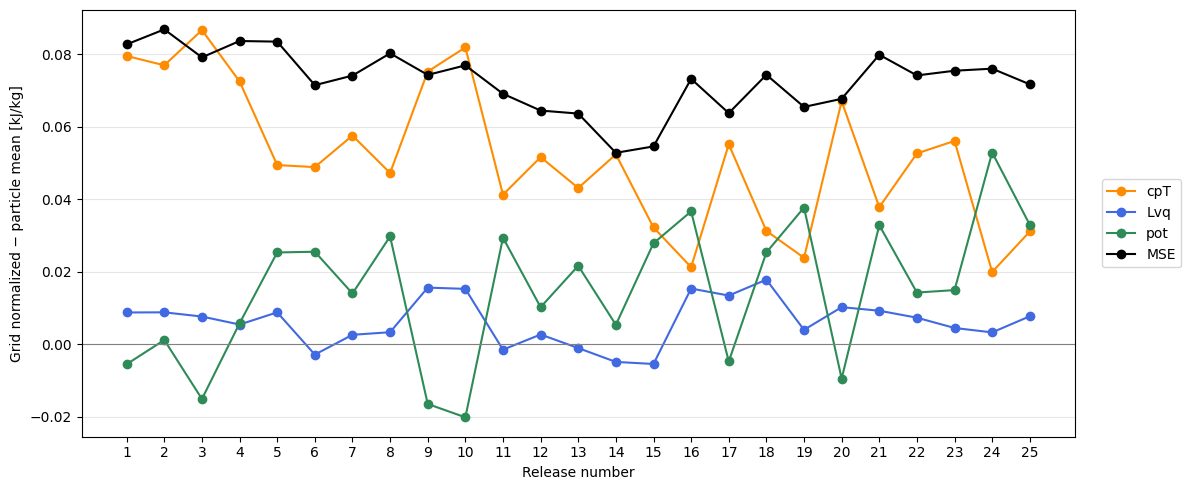

In [20]:
differences = comparison_all["difference_Jkg"].unstack("component")

fig, ax = plt.subplots(figsize=(12, 5))

for component, color in [
    ("cpT", "darkorange"),
    ("Lvq", "royalblue"),
    ("pot", "seagreen"),
    ("MSE", "black"),
]:
    ax.plot(
        differences.index,
        differences[component] / 1000,
        marker="o",
        color=color,
        label=component,
    )

ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xticks(differences.index)
ax.set_xlabel("Release number")
ax.set_ylabel("Grid normalized − particle mean [kJ/kg]")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))

plt.tight_layout()
plt.show()